# The Impact of COVID-19 on Nigerian Financial Markets
## A Statistical Analysis of Market Regime Shifts Using a Hidden Markov Model (2017–2025)

**MScFE 690 Capstone — WorldQuant University**
Authors: Towobola Oluwatunmise Moses; Abdurrahman Mubarak Derie; Jeffrey Ted Johnattan Mbonga Nkounga

**Data:** Brent crude oil, NGX All-Share Index, USD/NGN exchange rate, and Nigerian FGN bond yields (2Y, 5Y, 10Y, 20Y), 2017-01-01 to 2025-12-31 (files in `data/raw/`).

**Periods:** Pre-COVID (2017-01-01 to 2020-02-26), COVID (2020-02-27 to 2021-12-31), Post-COVID (2022-01-01 to 2025-12-31).

**Methods:** log returns and rolling volatility; ARIMA(1,0,1) and GARCH(1,1); PCA on yield changes; correlation analysis; Welch's t-test and Levene's test; two- and three-state Gaussian HMM; ADF/KPSS stationarity tests; out-of-sample HMM validation; robustness and economic-significance analysis.

In [1]:
# ============================================================
# STEP 0A — INSTALL DEPENDENCIES
# (Colab only. When running locally use:  pip install -r requirements.txt)
# ============================================================
import sys
if "google.colab" in sys.modules:
    !pip install -q arch hmmlearn


In [2]:
# ============================================================
# STEP 0B — IMPORTS, PATHS & CONFIGURATION
# ============================================================
import os
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import multivariate_normal

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss
from arch import arch_model
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from hmmlearn.hmm import GaussianHMM

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Paths. Google Colab: files live in /content/. Local clone: data/raw/ (inputs)
# and results/ (all outputs are written here).
# ------------------------------------------------------------
if "google.colab" in sys.modules:
    ROOT = "/content"
    DATA_DIR = "/content/"
    OUT_DIR  = "/content/results/"
else:
    ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
    DATA_DIR = os.path.join(ROOT, "data", "raw") + os.sep
    OUT_DIR  = os.path.join(ROOT, "results") + os.sep
os.makedirs(OUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# Configuration. Values are read from config.json (repository root) when it
# exists; the defaults below are identical to that file, so the notebook also
# runs in Colab without uploading it.
# ------------------------------------------------------------
CONFIG = {
    "start_date": "2017-01-01",
    "end_date": "2025-12-31",
    "periods": {"Pre-COVID": ["2017-01-01", "2020-02-26"],       # Proposal Section 3.2
                "COVID": ["2020-02-27", "2021-12-31"],
                "Post-COVID": ["2022-01-01", "2025-12-31"]},
    "naira_float_date": "2023-06-14",   # CBN FX-window unification (29 May 2023 subsidy removal used as robustness check)
    "n_restarts": 10,                   # random restarts for HMM model comparison and out-of-sample fits
    "fwd_window": 20,                   # forward realised-volatility horizon (trading days)
    "rolling_window": 20,               # rolling volatility window (trading days)
    "hmm_random_state": 42,
    "bond_columns": ["Nigeria_2Y_Bond_Yield", "Nigeria_5Y_Bond_Yield",
                     "Nigeria_10Y_Bond_Yield", "Nigeria_20Y_Bond_Yield"],
}
_cfg_path = os.path.join(ROOT, "config.json")
if os.path.exists(_cfg_path):
    with open(_cfg_path) as _f:
        CONFIG.update(json.load(_f))

START_DATE = CONFIG["start_date"]
END_DATE   = CONFIG["end_date"]
PERIODS    = {k: tuple(v) for k, v in CONFIG["periods"].items()}
PERIOD_PAIRS = [("Pre-COVID", "COVID"), ("COVID", "Post-COVID"), ("Pre-COVID", "Post-COVID")]
NAIRA_FLOAT_DATE = CONFIG["naira_float_date"]
N_RESTARTS = CONFIG["n_restarts"]
FWD_WINDOW = CONFIG["fwd_window"]
ROLLING_WINDOW = CONFIG["rolling_window"]
HMM_SEED = CONFIG["hmm_random_state"]
BOND_COLS  = CONFIG["bond_columns"]

def period_of(date):
    if date <= pd.Timestamp(PERIODS["Pre-COVID"][1]):
        return "Pre-COVID"
    elif date <= pd.Timestamp(PERIODS["COVID"][1]):
        return "COVID"
    return "Post-COVID"

def slice_period(series, start, end):
    return series.loc[start:end].dropna()

print("Libraries imported and configuration set.")

Libraries imported and configuration set.


## STEP 1 — Data collection

In [3]:
# ============================================================
# STEP 1 — DATA COLLECTION
# ============================================================
brent       = pd.read_csv(DATA_DIR + "Brent Oil.csv")
ngx         = pd.read_csv(DATA_DIR + "NGX All-Share Index (ASI).csv")
usd_ngn     = pd.read_csv(DATA_DIR + "USD_NGN Historical Data.csv")
bond_yields = pd.read_csv(DATA_DIR + "Nigeria_Bond_Yields_2017_2025_Redone.csv")

print("Raw dataset sizes:")
for name, df in {"Brent": brent, "NGX": ngx, "USD/NGN": usd_ngn, "Bonds": bond_yields}.items():
    print(f"  {name:8s} {df.shape}")
print("Bond columns:", bond_yields.columns.tolist())

Raw dataset sizes:
  Brent    (2536, 2)
  NGX      (2208, 7)
  USD/NGN  (2326, 7)
  Bonds    (2198, 5)
Bond columns: ['Date', 'Nigeria_2Y_Bond_Yield', 'Nigeria_5Y_Bond_Yield', 'Nigeria_10Y_Bond_Yield', 'Nigeria_20Y_Bond_Yield']


## STEP 2 — Cleaning & preparation

In [4]:
# ============================================================
# STEP 2 — DATA CLEANING & PREPARATION
# ============================================================
def clean_price_df(df):
    df = df.copy()
    df.columns = [c.replace("\ufeff", "").strip() for c in df.columns]   # strip BOM
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    df["Price"] = pd.to_numeric(df["Price"].astype(str).str.replace(",", "", regex=False),
                                errors="coerce")
    df = df.dropna(subset=["Date"]).sort_values("Date")
    df = df.drop_duplicates(subset="Date", keep="first")
    df = df[(df["Date"] >= START_DATE) & (df["Date"] <= END_DATE)]
    df = df.dropna(subset=["Price"])          # drop missing prices BEFORE computing returns
    return df.reset_index(drop=True)

brent   = clean_price_df(brent)
ngx     = clean_price_df(ngx)
usd_ngn = clean_price_df(usd_ngn)

bond_yields.columns = [c.replace("\ufeff", "").strip() for c in bond_yields.columns]
bond_yields["Date"] = pd.to_datetime(bond_yields["Date"], errors="coerce")
for c in BOND_COLS:
    bond_yields[c] = pd.to_numeric(bond_yields[c].astype(str).str.replace(",", "", regex=False),
                                   errors="coerce")
bond_yields = (bond_yields.dropna(subset=["Date"]).sort_values("Date")
               .drop_duplicates(subset="Date", keep="first"))
bond_yields = bond_yields[(bond_yields["Date"] >= START_DATE) & (bond_yields["Date"] <= END_DATE)]
bond_yields = bond_yields.reset_index(drop=True)

# Keep the full (not-jointly-filtered) bond table for per-tenor analysis in Step 11
bond_raw = bond_yields.copy()

# Joint-complete bond table (all four tenors present) — used for PCA & correlation
bond_joint = bond_yields.dropna(subset=BOND_COLS).reset_index(drop=True)

print("Cleaned sample sizes (prices / observations):")
print(f"  Brent   : {len(brent):5d}   {brent['Date'].min().date()} to {brent['Date'].max().date()}")
print(f"  NGX     : {len(ngx):5d}   {ngx['Date'].min().date()} to {ngx['Date'].max().date()}")
print(f"  USD/NGN : {len(usd_ngn):5d}   {usd_ngn['Date'].min().date()} to {usd_ngn['Date'].max().date()}")
print(f"  Bonds (all four tenors present): {len(bond_joint):5d} of {len(bond_raw)} dates")
print()
print("Per-tenor availability (individually cleaned):")
for c in BOND_COLS:
    print(f"  {c}: {bond_raw[c].notna().sum()} observations")
print()
print("Proposal reference values: Brent 2,283 | NGX 2,208 | USD/NGN 2,326 | joint bonds 1,319")

Cleaned sample sizes (prices / observations):
  Brent   :  2283   2017-01-03 to 2025-12-31
  NGX     :  2208   2017-01-03 to 2025-12-01
  USD/NGN :  2326   2017-01-02 to 2025-12-01
  Bonds (all four tenors present):  1319 of 2198 dates

Per-tenor availability (individually cleaned):
  Nigeria_2Y_Bond_Yield: 1797 observations
  Nigeria_5Y_Bond_Yield: 1682 observations
  Nigeria_10Y_Bond_Yield: 2147 observations
  Nigeria_20Y_Bond_Yield: 2140 observations

Proposal reference values: Brent 2,283 | NGX 2,208 | USD/NGN 2,326 | joint bonds 1,319


## STEP 3 — Exploratory data analysis


--- Brent: price summary ---
count    2283.0000
mean       70.5517
std        17.8648
min         9.1200
25%        61.0050
50%        70.8700
75%        80.9250
max       133.1800
Name: Price, dtype: float64

--- NGX All-Share: price summary ---
count      2208.0000
mean      54596.2146
std       32302.1328
min       20669.3800
25%       31202.7700
50%       41065.8750
75%       66590.6850
max      155645.0300
Name: Price, dtype: float64

--- USD/NGN: price summary ---
count    2326.0000
mean      629.8658
std       475.5793
min       304.0000
25%       305.9500
50%       409.8100
75%       773.0000
max      1681.3900
Name: Price, dtype: float64

--- Bond yields (joint-complete) ---
       Nigeria_2Y_Bond_Yield  Nigeria_5Y_Bond_Yield  Nigeria_10Y_Bond_Yield  \
count              1319.0000              1319.0000               1319.0000   
mean                 12.3264                13.3496                 14.1056   
std                   6.2651                 4.3118                  

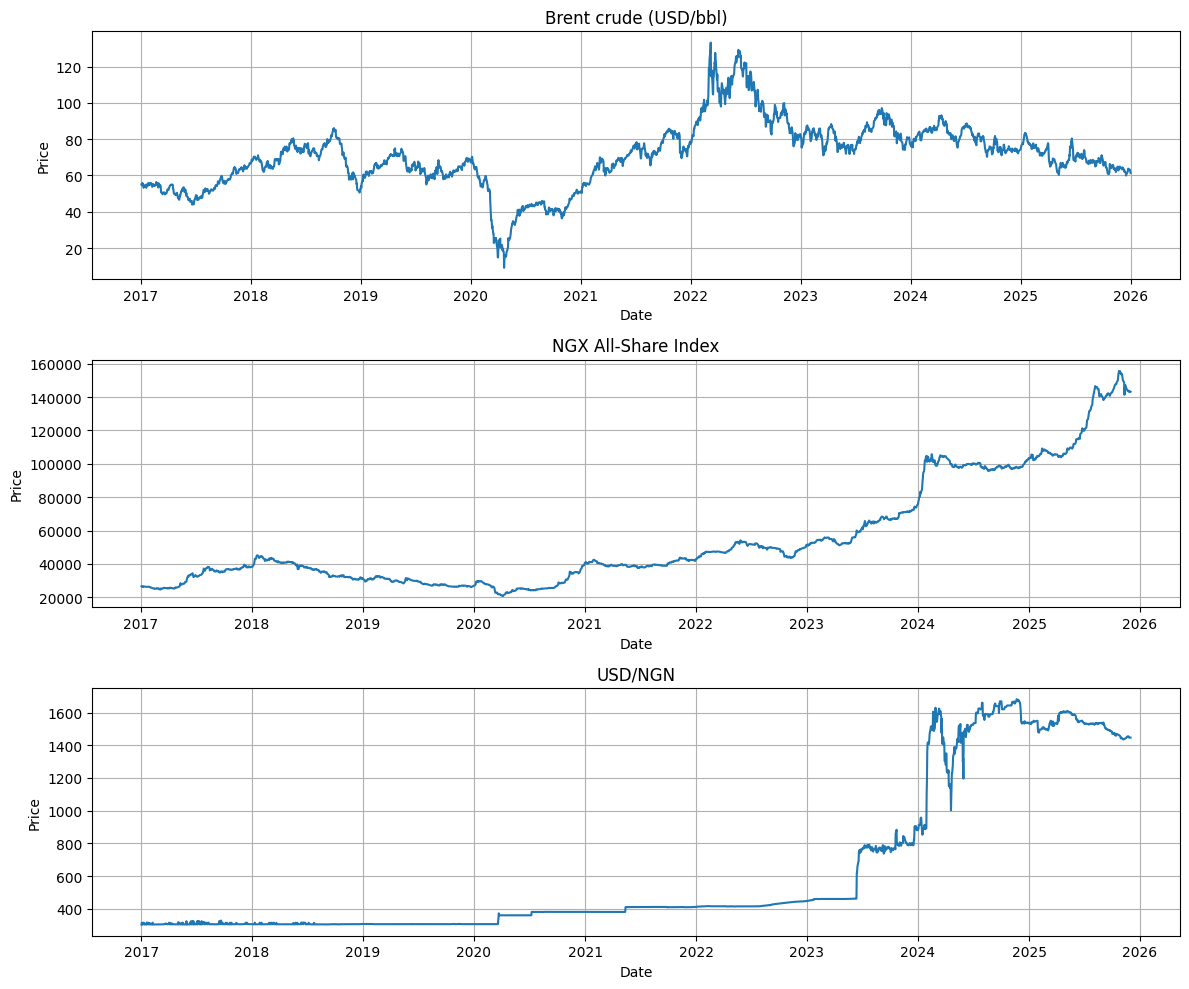

In [5]:
# ============================================================
# STEP 3 — EXPLORATORY DATA ANALYSIS
# ============================================================
for name, df in {"Brent": brent, "NGX All-Share": ngx, "USD/NGN": usd_ngn}.items():
    print(f"\n--- {name}: price summary ---")
    print(df["Price"].describe().round(4))

print("\n--- Bond yields (joint-complete) ---")
print(bond_joint[BOND_COLS].describe().round(4))

fig, axes = plt.subplots(3, 1, figsize=(12, 10))
for ax, (name, df) in zip(axes, {"Brent crude (USD/bbl)": brent,
                                 "NGX All-Share Index": ngx,
                                 "USD/NGN": usd_ngn}.items()):
    ax.plot(df["Date"], df["Price"])
    ax.set_title(name); ax.set_xlabel("Date"); ax.set_ylabel("Price"); ax.grid(True)
plt.tight_layout(); plt.show()

## STEP 4 — Returns & volatility

In [6]:
# ============================================================
# STEP 4 — RETURN & VOLATILITY
# ============================================================
for df in (brent, ngx, usd_ngn):
    df["Return"] = np.log(df["Price"] / df["Price"].shift(1))
    df["Volatility"] = df["Return"].rolling(ROLLING_WINDOW).std()      # 20-day rolling realised volatility

for c in BOND_COLS:
    bond_joint[f"{c}_Change"] = bond_joint[c].diff()

print("Largest single-day Brent moves (check the 2020-04-21 event):")
print(brent.loc[brent["Return"].abs().nlargest(5).index, ["Date", "Price", "Return"]]
      .round(4).to_string(index=False))

print("\nReturn statistics:")
for name, df in {"Brent": brent, "NGX": ngx, "USD/NGN": usd_ngn}.items():
    print(f"\n{name}")
    print(df["Return"].describe().round(6))

Largest single-day Brent moves (check the 2020-04-21 event):
      Date  Price  Return
2020-04-21   9.12 -0.6437
2020-04-22  13.77  0.4120
2020-04-02  20.24  0.3016
2020-03-31  14.85 -0.2564
2020-03-09  35.33 -0.2552

Return statistics:

Brent
count    2282.000000
mean        0.000047
std         0.031075
min        -0.643699
25%        -0.011249
50%         0.001257
75%         0.012724
max         0.412023
Name: Return, dtype: float64

NGX
count    2207.000000
mean        0.000762
std         0.008752
min        -0.051741
25%        -0.002788
50%         0.000237
75%         0.004085
max         0.060478
Name: Return, dtype: float64

USD/NGN
count    2325.000000
mean        0.000671
std         0.017118
min        -0.135614
25%        -0.000065
50%         0.000000
75%         0.000168
max         0.293655
Name: Return, dtype: float64


## STEP 5 — Time-series analysis (ARIMA and GARCH)

In [7]:
# ============================================================
# STEP 5A — ARIMA(1,0,1) on NGX log returns
# ============================================================
ngx_ret = ngx.set_index("Date")["Return"].dropna()

arima_result = ARIMA(ngx_ret, order=(1, 0, 1)).fit()
print(arima_result.summary())
print(f"\nAIC = {arima_result.aic:,.2f} | BIC = {arima_result.bic:,.2f}")
print(f"Kurtosis of ARIMA residuals (non-excess) = {stats.kurtosis(arima_result.resid, fisher=False):.2f}")
print(f"Kurtosis of raw NGX returns (non-excess)   = {stats.kurtosis(ngx_ret, fisher=False):.2f}")
print("Proposal reference: AIC = -14,789.30 | BIC = -14,766.50 | kurtosis = 8.16")

                               SARIMAX Results                                
Dep. Variable:                 Return   No. Observations:                 2207
Model:                 ARIMA(1, 0, 1)   Log Likelihood                7398.651
Date:                Tue, 27 Oct 2026   AIC                         -14789.302
Time:                        00:38:20   BIC                         -14766.504
Sample:                             0   HQIC                        -14780.973
                               - 2207                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0008      0.000      2.902      0.004       0.000       0.001
ar.L1          0.4733      0.052      9.074      0.000       0.371       0.576
ma.L1         -0.2453      0.059     -4.185      0.0

In [8]:
# ============================================================
# STEP 5B — GARCH(1,1) on NGX log returns (returns scaled to percent)
# ============================================================
garch_result = arch_model(ngx_ret * 100, mean="Constant", vol="GARCH", p=1, q=1,
                          dist="normal").fit(disp="off")
print(garch_result.summary())

omega = garch_result.params["omega"]
alpha = garch_result.params["alpha[1]"]
beta  = garch_result.params["beta[1]"]
print(f"\nomega = {omega:.4f} | alpha1 = {alpha:.4f} | beta1 = {beta:.4f}")
print(f"Volatility persistence (alpha + beta) = {alpha + beta:.4f}")
print("Proposal reference: omega = 0.0861 | alpha1 = 0.2090 | beta1 = 0.6903 | persistence = 0.8994")

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                 Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -2601.34
Distribution:                  Normal   AIC:                           5210.68
Method:            Maximum Likelihood   BIC:                           5233.48
                                        No. Observations:                 2207
Date:                Tue, Oct 27 2026   Df Residuals:                     2206
Time:                        00:38:20   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu             0.0281  1.648e-02      1.704  8.838e-02 

## STEP 6 — Sovereign yield-curve PCA

Observations used: 1318
Component  Explained_Variance_Ratio  Cumulative
      PC1                    0.3707      0.3707
      PC2                    0.2260      0.5967
      PC3                    0.2079      0.8046
      PC4                    0.1954      1.0000
Proposal reference: PC1 = 37.07% | PC1-3 = 80.46%

Loadings:
                           PC1     PC2     PC3     PC4
Nigeria_2Y_Bond_Yield   0.4916 -0.3964  0.7716  0.0758
Nigeria_5Y_Bond_Yield   0.5370 -0.2556 -0.4053 -0.6944
Nigeria_10Y_Bond_Yield  0.5444 -0.0630 -0.4485  0.7060
Nigeria_20Y_Bond_Yield  0.4166  0.8795  0.1979 -0.1171


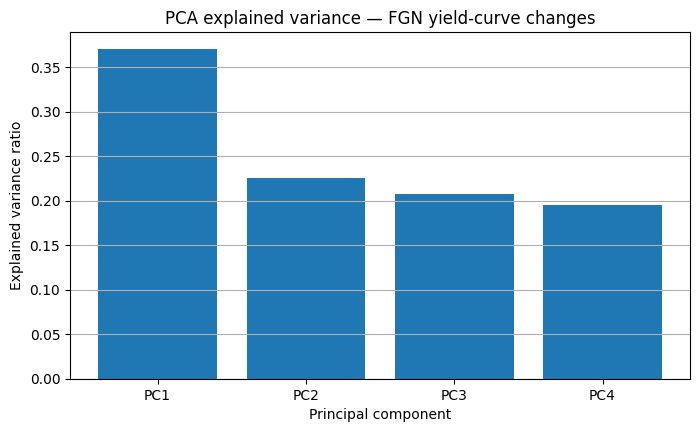

In [9]:
# ============================================================
# STEP 6 — PCA ON STANDARDISED DAILY YIELD CHANGES (joint-complete dates)
# ============================================================
yield_changes = bond_joint[BOND_COLS].diff().dropna()
yield_scaled = StandardScaler().fit_transform(yield_changes)

pca = PCA()
pca_scores = pca.fit_transform(yield_scaled)

explained = pd.DataFrame({
    "Component": ["PC1", "PC2", "PC3", "PC4"],
    "Explained_Variance_Ratio": pca.explained_variance_ratio_,
    "Cumulative": np.cumsum(pca.explained_variance_ratio_),
})
print(f"Observations used: {len(yield_changes)}")
print(explained.round(4).to_string(index=False))
print("Proposal reference: PC1 = 37.07% | PC1-3 = 80.46%")

loadings = pd.DataFrame(pca.components_.T, index=BOND_COLS, columns=["PC1", "PC2", "PC3", "PC4"])
print("\nLoadings:")
print(loadings.round(4))

plt.figure(figsize=(8, 4.5))
plt.bar(explained["Component"], explained["Explained_Variance_Ratio"])
plt.title("PCA explained variance — FGN yield-curve changes")
plt.xlabel("Principal component"); plt.ylabel("Explained variance ratio")
plt.grid(axis="y"); plt.show()

## STEP 7 — Cross-market correlation (on returns and yield changes, not levels)

In [10]:
# ============================================================
# STEP 7 — CORRELATION ANALYSIS
# ============================================================
yc = bond_joint.set_index("Date")[BOND_COLS].diff()
yc.columns = [c.replace("Nigeria_", "").replace("_Bond_Yield", "") + "_chg" for c in BOND_COLS]

corr_data = pd.concat([
    ngx.set_index("Date")["Return"].rename("NGX"),
    usd_ngn.set_index("Date")["Return"].rename("USD_NGN"),
    brent.set_index("Date")["Return"].rename("Brent"),
    yc,
], axis=1, sort=True).dropna()

corr_matrix = corr_data.corr()
print(f"Observations: {len(corr_data)}")
print(corr_matrix.round(4))

market_cols = ["NGX", "USD_NGN", "Brent"]
bond_chg_cols = list(yc.columns)
pairs = []
for i, a in enumerate(market_cols):
    for b_ in market_cols[i + 1:] + bond_chg_cols:       # market-vs-market and market-vs-bond only
        pairs.append((a, b_, corr_matrix.loc[a, b_]))
cross = pd.DataFrame(pairs, columns=["Series A", "Series B", "Correlation"])
cross["|Correlation|"] = cross["Correlation"].abs()
top = cross.sort_values("|Correlation|", ascending=False).iloc[0]
print(f"\nLargest |cross-market correlation| = {top['|Correlation|']:.4f} ({top['Series A']} vs {top['Series B']})")
print(f"NGX–Brent = {corr_matrix.loc['NGX', 'Brent']:.4f}")
corr_matrix.round(4).to_csv(OUT_DIR + "correlation_matrix.csv")
print("Proposal reference: largest cross-market correlation 0.078 (NGX–Brent)")

Observations: 1306
            NGX  USD_NGN   Brent  2Y_chg  5Y_chg  10Y_chg  20Y_chg
NGX      1.0000   0.0435  0.0780 -0.0196 -0.0485  -0.0148  -0.0364
USD_NGN  0.0435   1.0000 -0.0232 -0.0107  0.0107   0.0258   0.0115
Brent    0.0780  -0.0232  1.0000  0.0023  0.0218  -0.0165   0.0320
2Y_chg  -0.0196  -0.0107  0.0023  1.0000  0.1831   0.1734   0.1087
5Y_chg  -0.0485   0.0107  0.0218  0.1831  1.0000   0.2171   0.1227
10Y_chg -0.0148   0.0258 -0.0165  0.1734  0.2171   1.0000   0.1481
20Y_chg -0.0364   0.0115  0.0320  0.1087  0.1227   0.1481   1.0000

Largest |cross-market correlation| = 0.0780 (NGX vs Brent)
NGX–Brent = 0.0780
Proposal reference: largest cross-market correlation 0.078 (NGX–Brent)


## STEP 8 — Two-state Gaussian HMM (states relabelled by mean volatility)

In [11]:
# ============================================================
# STEP 8 — HMM REGIME DETECTION (2 states)
# ============================================================
hmm_data = ngx[["Date", "Return", "Volatility"]].dropna().copy().reset_index(drop=True)

hmm_scaler = StandardScaler()
hmm_features = hmm_scaler.fit_transform(hmm_data[["Return", "Volatility"]])

hmm_model = GaussianHMM(n_components=2, covariance_type="full", n_iter=1000, random_state=HMM_SEED)
hmm_model.fit(hmm_features)
hmm_data["Regime"] = hmm_model.predict(hmm_features)      # arbitrary hmmlearn index (0/1)

# --- CRITICAL: label states by their mean realised volatility, never by index ---
state_mean_vol = hmm_data.groupby("Regime")["Volatility"].mean()
high_id, low_id = state_mean_vol.idxmax(), state_mean_vol.idxmin()
label_map = {high_id: "High-Volatility", low_id: "Low-Volatility"}
hmm_data["State"] = hmm_data["Regime"].map(label_map)
hmm_data["Period"] = hmm_data["Date"].apply(period_of)

print("Mean 20-day volatility by state:")
print(state_mean_vol.rename(index=label_map).round(4))
print("Proposal reference: High = 0.0116 | Low = 0.0053")

order = [label_map[low_id], label_map[high_id]]
tm = pd.DataFrame(hmm_model.transmat_, index=[label_map[i] for i in range(2)],
                  columns=[label_map[i] for i in range(2)]).loc[order, order]
print("\nTransition matrix (rows = from, columns = to):")
print(tm.round(4))

share = (pd.crosstab(hmm_data["Period"], hmm_data["State"], normalize="index") * 100)
share = share.loc[["Pre-COVID", "COVID", "Post-COVID"], ["High-Volatility", "Low-Volatility"]]
print("\nShare of trading days by state and period (%):")
print(share.round(2))
print("Proposal reference (High-Vol): Pre 49.87 | COVID 32.60 | Post 23.74")

share.round(2).to_csv(OUT_DIR + "hmm_2state_regime_shares.csv")

Mean 20-day volatility by state:
Regime
High-Volatility    0.0116
Low-Volatility     0.0053
Name: Volatility, dtype: float64
Proposal reference: High = 0.0116 | Low = 0.0053

Transition matrix (rows = from, columns = to):
                 Low-Volatility  High-Volatility
Low-Volatility           0.9856           0.0144
High-Volatility          0.0260           0.9740

Share of trading days by state and period (%):
State       High-Volatility  Low-Volatility
Period                                     
Pre-COVID             49.87           50.13
COVID                 32.60           67.40
Post-COVID            23.74           76.26
Proposal reference (High-Vol): Pre 49.87 | COVID 32.60 | Post 23.74


## STEP 9 — Per-tenor bond cleaning

In [12]:
# ============================================================
# STEP 9 — INDIVIDUALLY-CLEANED BOND TENORS
# ============================================================
bond_single = {}
for c in BOND_COLS:
    s = bond_raw[["Date", c]].dropna().reset_index(drop=True)
    s[c + "_Change"] = s[c].diff()
    bond_single[c] = s
    print(f"{c}: {len(s)} observations (joint-complete matrix has {len(bond_joint)})")

Nigeria_2Y_Bond_Yield: 1797 observations (joint-complete matrix has 1319)
Nigeria_5Y_Bond_Yield: 1682 observations (joint-complete matrix has 1319)
Nigeria_10Y_Bond_Yield: 2147 observations (joint-complete matrix has 1319)
Nigeria_20Y_Bond_Yield: 2140 observations (joint-complete matrix has 1319)


## STEP 10 — Full Welch's t-test / Levene's test table

In [13]:
# ============================================================
# STEP 10 — WELCH'S t-TEST AND LEVENE'S TEST: ALL SERIES x ALL PERIOD PAIRS
# ============================================================
series_for_testing = {
    "NGX returns":            ngx.set_index("Date")["Return"],
    "NGX rolling volatility": ngx.set_index("Date")["Volatility"],
    "USD/NGN returns":        usd_ngn.set_index("Date")["Return"],
    "Brent returns":          brent.set_index("Date")["Return"],
}
for c, label in zip(BOND_COLS, ["2Y", "5Y", "10Y", "20Y"]):
    series_for_testing[f"{label} bond yield change"] = (
        bond_single[c].set_index("Date")[c + "_Change"])

rows = []
for name, s in series_for_testing.items():
    for p1, p2 in PERIOD_PAIRS:
        a = slice_period(s, *PERIODS[p1])
        b = slice_period(s, *PERIODS[p2])
        t_stat, t_p = stats.ttest_ind(a, b, equal_var=False, nan_policy="omit")
        lev_stat, lev_p = stats.levene(a, b, center="median")
        rows.append({
            "Series": name, "Period A": p1, "Period B": p2,
            "n (A)": len(a), "n (B)": len(b),
            "mean (A)": a.mean(), "mean (B)": b.mean(),
            "std (A)": a.std(), "std (B)": b.std(),
            "Welch t": t_stat, "Welch p": t_p,
            "Levene W": lev_stat, "Levene p": lev_p,
            "Variance differs (5%)": lev_p < 0.05,
            "Mean differs (5%)": t_p < 0.05,
        })

wl = pd.DataFrame(rows)
wl.to_csv(OUT_DIR + "welch_levene_full_table.csv", index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(f"{len(wl)} rows ({len(series_for_testing)} series x {len(PERIOD_PAIRS)} period pairs)\n")
print(wl.round(6).to_string(index=False))
print(f"\nVariance significantly different in {int(wl['Variance differs (5%)'].sum())} of {len(wl)} comparisons")
print(f"Mean significantly different     in {int(wl['Mean differs (5%)'].sum())} of {len(wl)} comparisons")
print("\nNOTE: rolling-volatility windows overlap (20-day), so its p-values are optimistic — see the")
print("serial-dependence limitation already stated in Proposal Section 4.6.")

24 rows (8 series x 3 period pairs)

                Series  Period A   Period B  n (A)  n (B)  mean (A)  mean (B)  std (A)  std (B)   Welch t  Welch p  Levene W  Levene p  Variance differs (5%)  Mean differs (5%)
           NGX returns Pre-COVID      COVID    781    457  0.000017  0.001006 0.009353 0.009495 -1.778039 0.075720  3.379367  0.066257                  False              False
           NGX returns     COVID Post-COVID    457    969  0.001006  0.001248 0.009495 0.007804 -0.475538 0.634541  4.700290  0.030323                   True              False
           NGX returns Pre-COVID Post-COVID    781    969  0.000017  0.001248 0.009353 0.007804 -2.944716 0.003282 26.396185  0.000000                   True               True
NGX rolling volatility Pre-COVID      COVID    762    457  0.008541  0.007903 0.003395 0.004094  2.802157 0.005195  1.454210  0.228088                  False               True
NGX rolling volatility     COVID Post-COVID    457    969  0.007903  0.006537 

## STEP 11 — Naira-float / subsidy-removal sub-period split

In [14]:
# ============================================================
# STEP 11 — SUB-PERIOD SPLIT AT THE 2023 NAIRA FLOAT
# ============================================================
float_date = pd.Timestamp(NAIRA_FLOAT_DATE)
SUBPERIODS = {
    "Post-COVID, pre-float":  ("2022-01-01", NAIRA_FLOAT_DATE),
    "Post-COVID, post-float": ((float_date + pd.Timedelta(days=1)).strftime("%Y-%m-%d"), END_DATE),
}

state_series = hmm_data.set_index("Date")["State"]
rows = []
for name, (start, end) in {**PERIODS, **SUBPERIODS}.items():
    sub = state_series.loc[start:end]
    hi = (sub == "High-Volatility").mean() * 100
    rows.append({"Period": name, "n days": len(sub),
                 "High-Volatility share (%)": round(hi, 2),
                 "Low-Volatility share (%)": round(100 - hi, 2)})
naira_table = pd.DataFrame(rows)
naira_table.to_csv(OUT_DIR + "naira_float_subperiod_regime_shares.csv", index=False)
print(naira_table.to_string(index=False))

pre_name, post_name = list(SUBPERIODS)
tests = []
for label, s in {"NGX returns": ngx.set_index("Date")["Return"],
                 "NGX rolling volatility": ngx.set_index("Date")["Volatility"]}.items():
    a = slice_period(s, *SUBPERIODS[pre_name]); b = slice_period(s, *SUBPERIODS[post_name])
    t_stat, t_p = stats.ttest_ind(a, b, equal_var=False)
    lev, lev_p = stats.levene(a, b, center="median")
    tests.append({"Series": label, "n pre": len(a), "n post": len(b),
                  "mean pre": a.mean(), "mean post": b.mean(),
                  "std pre": a.std(), "std post": b.std(),
                  "Welch t": t_stat, "Welch p": t_p, "Levene W": lev, "Levene p": lev_p})
naira_tests = pd.DataFrame(tests)
naira_tests.to_csv(OUT_DIR + "naira_float_break_tests.csv", index=False)
print("\nWelch / Levene across the float date:")
print(naira_tests.round(6).to_string(index=False))

# Does the 2-state regime share differ across the break? (simple two-proportion z-test)
x1 = (state_series.loc[SUBPERIODS[pre_name][0]:SUBPERIODS[pre_name][1]] == "High-Volatility")
x2 = (state_series.loc[SUBPERIODS[post_name][0]:SUBPERIODS[post_name][1]] == "High-Volatility")
p1, p2, n1, n2 = x1.mean(), x2.mean(), len(x1), len(x2)
pp = (x1.sum() + x2.sum()) / (n1 + n2)
z = (p1 - p2) / np.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2))
print(f"\nHigh-vol share pre-float {p1:.1%} vs post-float {p2:.1%}: z = {z:.2f}, p = {2 * (1 - stats.norm.cdf(abs(z))):.4f}")
print("(regime labels are serially dependent, so treat this p-value as indicative only)")

                Period  n days  High-Volatility share (%)  Low-Volatility share (%)
             Pre-COVID     762                      49.87                     50.13
                 COVID     457                      32.60                     67.40
            Post-COVID     969                      23.74                     76.26
 Post-COVID, pre-float     358                      32.96                     67.04
Post-COVID, post-float     611                      18.33                     81.67

Welch / Levene across the float date:
                Series  n pre  n post  mean pre  mean post  std pre  std post   Welch t  Welch p  Levene W  Levene p
           NGX returns    358     611  0.000948   0.001424 0.008045  0.007660 -0.904516 0.366025  0.268597  0.604393
NGX rolling volatility    358     611  0.006729   0.006425 0.002757  0.003669  1.461952 0.144100  4.535959  0.033442

High-vol share pre-float 33.0% vs post-float 18.3%: z = 5.17, p = 0.0000
(regime labels are serially depe

## STEP 12 — Three-state HMM versus two-state HMM

In [15]:
# ============================================================
# STEP 12 — 3-STATE HMM vs 2-STATE HMM
# ============================================================
def n_free_params(K, d):
    # transitions K(K-1) + start probs (K-1) + means K*d + full covariances K*d(d+1)/2
    return K * (K - 1) + (K - 1) + K * d + K * d * (d + 1) // 2

def best_of_restarts(X, K, n_restarts=N_RESTARTS):
    best = None
    for seed in range(n_restarts):
        m = GaussianHMM(n_components=K, covariance_type="full", n_iter=1000, random_state=seed)
        try:
            m.fit(X); ll = m.score(X)
        except Exception:
            continue
        if best is None or ll > best[1]:
            best = (m, ll)
    return best

n_obs, d = hmm_features.shape
fits = {}
for K in (2, 3):
    m, ll = best_of_restarts(hmm_features, K)
    k = n_free_params(K, d)
    fits[K] = {"model": m, "logL": ll, "params": k,
               "AIC": -2 * ll + 2 * k, "BIC": -2 * ll + k * np.log(n_obs)}

comparison = pd.DataFrame({K: {"log-likelihood": f["logL"], "free parameters": f["params"],
                               "AIC": f["AIC"], "BIC": f["BIC"]} for K, f in fits.items()}).T
comparison.index = ["2-state", "3-state"]
comparison.to_csv(OUT_DIR + "hmm_2_vs_3_state_fit.csv")
print(f"Best of {N_RESTARTS} random restarts per model (lower AIC/BIC is better):")
print(comparison.round(2))

# Label the three states by mean volatility: lowest -> Low, middle -> Medium, highest -> High
m3 = fits[3]["model"]
d3 = hmm_data[["Date", "Volatility"]].copy()
d3["Regime3"] = m3.predict(hmm_features)
order3 = d3.groupby("Regime3")["Volatility"].mean().sort_values().index.tolist()
map3 = {order3[0]: "Low-Volatility", order3[1]: "Medium-Volatility", order3[2]: "High-Volatility"}
d3["State3"] = d3["Regime3"].map(map3)
d3["Period"] = d3["Date"].apply(period_of)

print("\nMean 20-day volatility by 3-state label:")
print(d3.groupby("State3")["Volatility"].mean().round(4))

share3 = (pd.crosstab(d3["Period"], d3["State3"], normalize="index") * 100)
share3 = share3.loc[["Pre-COVID", "COVID", "Post-COVID"],
                    ["Low-Volatility", "Medium-Volatility", "High-Volatility"]]
print("\n3-state regime share by period (%):")
print(share3.round(2))
share3.round(2).to_csv(OUT_DIR + "hmm_3state_regime_shares.csv")

tm3 = pd.DataFrame(m3.transmat_, index=[map3[i] for i in range(3)], columns=[map3[i] for i in range(3)])
tm3 = tm3.loc[list(map3.values()), list(map3.values())]
print("\n3-state transition matrix:")
print(tm3.round(4))
tm3.round(4).to_csv(OUT_DIR + "hmm_3state_transition_matrix.csv")

Best of 10 random restarts per model (lower AIC/BIC is better):
         log-likelihood  free parameters      AIC      BIC
2-state        -4668.79             13.0  9363.58  9437.56
3-state        -3922.76             23.0  7891.51  8022.40

Mean 20-day volatility by 3-state label:
State3
High-Volatility      0.0121
Low-Volatility       0.0037
Medium-Volatility    0.0066
Name: Volatility, dtype: float64

3-state regime share by period (%):
State3      Low-Volatility  Medium-Volatility  High-Volatility
Period                                                        
Pre-COVID            13.25              44.49            42.26
COVID                18.16              51.64            30.20
Post-COVID           39.94              38.80            21.26

3-state transition matrix:
                   Low-Volatility  Medium-Volatility  High-Volatility
Low-Volatility             0.9530             0.0439           0.0031
Medium-Volatility          0.0274             0.9546           0.0181
Hig

## STEP 13 — Stationarity checks (ADF and KPSS)

In [16]:
# ============================================================
# STEP 13 — ADF (H0: unit root) AND KPSS (H0: stationary)
# Reading both together:  ADF rejects & KPSS does not reject  -> stationary
#                         ADF does not reject & KPSS rejects   -> non-stationary (unit root)
# ============================================================
def stationarity_row(name, series, kind):
    x = pd.Series(series).dropna().values
    row = {"Series": name, "Transform": kind, "n": len(x)}
    try:
        adf_stat, adf_p, *_ = adfuller(x, autolag="AIC")
        row.update({"ADF stat": adf_stat, "ADF p": adf_p})
    except Exception as e:
        row.update({"ADF stat": np.nan, "ADF p": np.nan})
    try:
        kpss_stat, kpss_p, *_ = kpss(x, regression="c", nlags="auto")
        row.update({"KPSS stat": kpss_stat, "KPSS p (bounded 0.01-0.10)": kpss_p})
    except Exception as e:
        row.update({"KPSS stat": np.nan, "KPSS p (bounded 0.01-0.10)": np.nan})
    adf_stationary = row["ADF p"] < 0.05
    kpss_stationary = row["KPSS p (bounded 0.01-0.10)"] > 0.05
    if adf_stationary and kpss_stationary:
        verdict = "Stationary"
    elif (not adf_stationary) and (not kpss_stationary):
        verdict = "Non-stationary"
    else:
        verdict = "Mixed / inconclusive"
    row["Verdict (5%)"] = verdict
    return row

rows = []
for c, lab in zip(BOND_COLS, ["2Y", "5Y", "10Y", "20Y"]):
    s = bond_joint[c]
    rows.append(stationarity_row(f"{lab} FGN yield", s, "level"))
    rows.append(stationarity_row(f"{lab} FGN yield", s.diff(), "daily change (PCA input)"))

rows.append(stationarity_row("NGX All-Share", ngx["Price"], "level"))
rows.append(stationarity_row("NGX All-Share", ngx["Return"], "log return (HMM input)"))
rows.append(stationarity_row("NGX All-Share", ngx["Volatility"], "20-day rolling volatility (HMM input)"))
rows.append(stationarity_row("USD/NGN", usd_ngn["Price"], "level"))
rows.append(stationarity_row("USD/NGN", usd_ngn["Return"], "log return"))
rows.append(stationarity_row("Brent", brent["Price"], "level"))
rows.append(stationarity_row("Brent", brent["Return"], "log return"))

stationarity = pd.DataFrame(rows)
stationarity.to_csv(OUT_DIR + "stationarity_adf_kpss.csv", index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(stationarity.round(4).to_string(index=False))
print("\nKPSS p-values are interpolated from a table and are bounded to the range 0.01-0.10.")

       Series                             Transform    n  ADF stat  ADF p  KPSS stat  KPSS p (bounded 0.01-0.10)         Verdict (5%)
 2Y FGN yield                                 level 1319   -1.4411 0.5624     3.8807                        0.01       Non-stationary
 2Y FGN yield              daily change (PCA input) 1318   -7.8847 0.0000     0.1219                        0.10           Stationary
 5Y FGN yield                                 level 1319   -1.2062 0.6709     4.1986                        0.01       Non-stationary
 5Y FGN yield              daily change (PCA input) 1318  -34.8796 0.0000     0.1239                        0.10           Stationary
10Y FGN yield                                 level 1319   -1.3413 0.6101     4.1179                        0.01       Non-stationary
10Y FGN yield              daily change (PCA input) 1318  -12.2461 0.0000     0.1439                        0.10           Stationary
20Y FGN yield                                 level 1319   -1.

## STEP 14 — Correlations by period (with confidence intervals) and tests of change

In [17]:
# ============================================================
# STEP 14A — LONG-SAMPLE MARKET CORRELATIONS (NGX, USD/NGN, Brent) BY PERIOD
# (no bond data needed, so the Pre-COVID window starts in 2017)
# ============================================================
def fisher_ci(r, n, z_crit=1.959964):
    if n <= 3 or not np.isfinite(r):
        return np.nan, np.nan
    z = np.arctanh(r); se = 1 / np.sqrt(n - 3)
    return np.tanh(z - z_crit * se), np.tanh(z + z_crit * se)

def corr_rows(data, pairs, label):
    out = []
    for per, (start, end) in PERIODS.items():
        sub = data.loc[start:end]
        for a, b in pairs:
            pair = sub[[a, b]].dropna()
            n = len(pair)
            if n < 10:
                continue
            r, p = stats.pearsonr(pair[a], pair[b])
            lo, hi = fisher_ci(r, n)
            out.append({"Sample": label, "Period": per, "Pair": f"{a} vs {b}", "n": n,
                        "r": r, "95% CI low": lo, "95% CI high": hi, "p (H0: r=0)": p})
    return pd.DataFrame(out)

mk = pd.concat([ngx.set_index("Date")["Return"].rename("NGX"),
                usd_ngn.set_index("Date")["Return"].rename("USD_NGN"),
                brent.set_index("Date")["Return"].rename("Brent")], axis=1, sort=True).dropna()
mk_pairs = [("NGX", "USD_NGN"), ("NGX", "Brent"), ("USD_NGN", "Brent")]
mk_corr = corr_rows(mk, mk_pairs, "3 markets, full sample (2017-)")
print(mk_corr.round(4).to_string(index=False))

                        Sample     Period             Pair   n       r  95% CI low  95% CI high  p (H0: r=0)
3 markets, full sample (2017-)  Pre-COVID   NGX vs USD_NGN 776  0.0524     -0.0181       0.1223       0.1450
3 markets, full sample (2017-)  Pre-COVID     NGX vs Brent 776  0.0183     -0.0521       0.0886       0.6108
3 markets, full sample (2017-)  Pre-COVID USD_NGN vs Brent 776 -0.0066     -0.0769       0.0638       0.8552
3 markets, full sample (2017-)      COVID   NGX vs USD_NGN 453 -0.1018     -0.1921      -0.0097       0.0303
3 markets, full sample (2017-)      COVID     NGX vs Brent 453  0.1294      0.0377       0.2189       0.0058
3 markets, full sample (2017-)      COVID USD_NGN vs Brent 453 -0.0586     -0.1499       0.0337       0.2133
3 markets, full sample (2017-) Post-COVID   NGX vs USD_NGN 958  0.0202     -0.0432       0.0835       0.5317
3 markets, full sample (2017-) Post-COVID     NGX vs Brent 958  0.0095     -0.0538       0.0728       0.7679
3 markets, full sam

In [18]:
# ============================================================
# STEP 14B — CROSS-MARKET CORRELATIONS INCLUDING BOND YIELD CHANGES
# (bond data are jointly complete only from mid-2019, so the Pre-COVID window is short — check n)
# ============================================================
yc = bond_joint.set_index("Date")[BOND_COLS].diff()
yc.columns = [c.replace("Nigeria_", "").replace("_Bond_Yield", "") + "_chg" for c in BOND_COLS]
allv = pd.concat([mk, yc], axis=1, sort=True).dropna()

cross_pairs = [(a, b) for a in ["NGX", "USD_NGN", "Brent"]
               for b in ["USD_NGN", "Brent"] + list(yc.columns) if a != b and (b, a) not in [(a, b)]]
# keep each unordered pair once
seen, cross_pairs_u = set(), []
for a, b in cross_pairs:
    key = frozenset((a, b))
    if key not in seen:
        seen.add(key); cross_pairs_u.append((a, b))

bond_corr = corr_rows(allv, cross_pairs_u, "markets + bond yield changes (joint-complete)")
print(f"Joint sample size by period:")
print(allv.groupby(allv.index.map(period_of)).size())
print()
print(bond_corr.round(4).to_string(index=False))

corr_all = pd.concat([mk_corr, bond_corr], ignore_index=True)
corr_all.to_csv(OUT_DIR + "correlation_by_period.csv", index=False)

Joint sample size by period:
Date
COVID         337
Post-COVID    841
Pre-COVID     128
dtype: int64

                                       Sample     Period               Pair   n       r  95% CI low  95% CI high  p (H0: r=0)
markets + bond yield changes (joint-complete)  Pre-COVID     NGX vs USD_NGN 128 -0.0506     -0.2221       0.1241       0.5709
markets + bond yield changes (joint-complete)  Pre-COVID       NGX vs Brent 128 -0.0661     -0.2369       0.1087       0.4583
markets + bond yield changes (joint-complete)  Pre-COVID      NGX vs 2Y_chg 128 -0.0797     -0.2498       0.0952       0.3713
markets + bond yield changes (joint-complete)  Pre-COVID      NGX vs 5Y_chg 128  0.0098     -0.1640       0.1830       0.9129
markets + bond yield changes (joint-complete)  Pre-COVID     NGX vs 10Y_chg 128  0.0472     -0.1274       0.2189       0.5968
markets + bond yield changes (joint-complete)  Pre-COVID     NGX vs 20Y_chg 128  0.0043     -0.1694       0.1777       0.9620
markets + bond y

                                       Sample               Pair  Period A   Period B   r (A)   r (B)  n (A)  n (B)       z      p  Changed (5%)
               3 markets, full sample (2017-)       NGX vs Brent Pre-COVID      COVID  0.0183  0.1294    776    453 -1.8863 0.0593         False
               3 markets, full sample (2017-)       NGX vs Brent     COVID Post-COVID  0.1294  0.0095    453    958  2.1092 0.0349          True
               3 markets, full sample (2017-)       NGX vs Brent Pre-COVID Post-COVID  0.0183  0.0095    776    958  0.1809 0.8565         False
               3 markets, full sample (2017-)     NGX vs USD_NGN Pre-COVID      COVID  0.0524 -0.1018    776    453  2.6065 0.0091          True
               3 markets, full sample (2017-)     NGX vs USD_NGN     COVID Post-COVID -0.1018  0.0202    453    958 -2.1402 0.0323          True
               3 markets, full sample (2017-)     NGX vs USD_NGN Pre-COVID Post-COVID  0.0524  0.0202    776    958  0.6651 0.5060

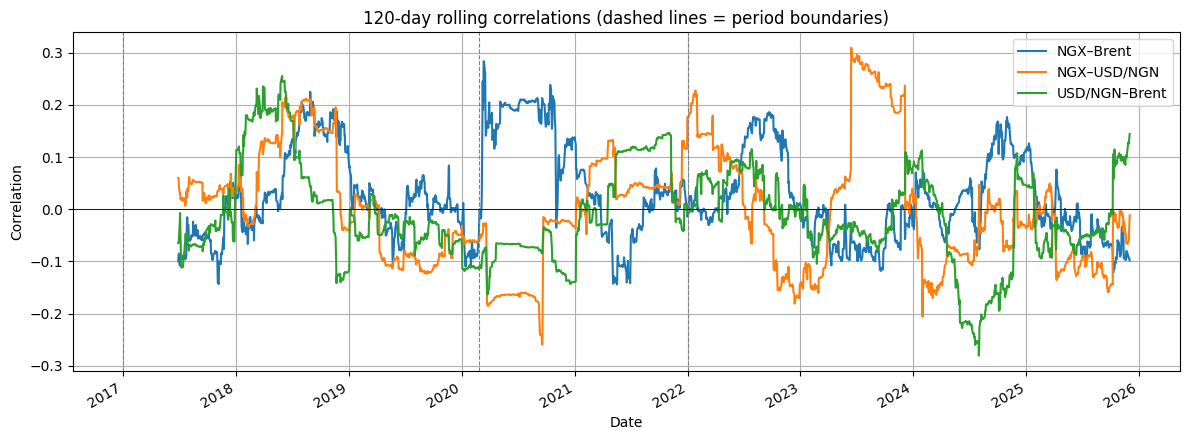

In [19]:
# ============================================================
# STEP 14C — DID CORRELATIONS CHANGE BETWEEN PERIODS? (Fisher z-test for independent samples)
# ============================================================
rows = []
for (sample, pair), g in corr_all.groupby(["Sample", "Pair"]):
    g = g.set_index("Period")
    for p1, p2 in PERIOD_PAIRS:
        if p1 not in g.index or p2 not in g.index:
            continue
        r1, n1, r2, n2 = g.loc[p1, "r"], g.loc[p1, "n"], g.loc[p2, "r"], g.loc[p2, "n"]
        z = (np.arctanh(r1) - np.arctanh(r2)) / np.sqrt(1 / (n1 - 3) + 1 / (n2 - 3))
        p = 2 * (1 - stats.norm.cdf(abs(z)))
        rows.append({"Sample": sample, "Pair": pair, "Period A": p1, "Period B": p2,
                     "r (A)": r1, "r (B)": r2, "n (A)": n1, "n (B)": n2, "z": z, "p": p,
                     "Changed (5%)": p < 0.05})
corr_change = pd.DataFrame(rows)
corr_change.to_csv(OUT_DIR + "correlation_change_tests.csv", index=False)
print(corr_change.round(4).to_string(index=False))
print(f"\n{int(corr_change['Changed (5%)'].sum())} of {len(corr_change)} period-to-period comparisons "
      f"differ at the 5% level (no multiple-testing correction applied).")

# 120-day rolling correlations, for a visual check of stability over time
roll = pd.DataFrame({
    "NGX–Brent": mk["NGX"].rolling(120).corr(mk["Brent"]),
    "NGX–USD/NGN": mk["NGX"].rolling(120).corr(mk["USD_NGN"]),
    "USD/NGN–Brent": mk["USD_NGN"].rolling(120).corr(mk["Brent"]),
})
fig, ax = plt.subplots(figsize=(12, 4.5))
roll.plot(ax=ax)
for lab, (s, e) in PERIODS.items():
    ax.axvline(pd.Timestamp(s), color="grey", ls="--", lw=0.8)
ax.axhline(0, color="black", lw=0.6)
ax.set_title("120-day rolling correlations (dashed lines = period boundaries)")
ax.set_xlabel("Date"); ax.set_ylabel("Correlation"); ax.grid(True)
plt.tight_layout(); plt.savefig(OUT_DIR + "rolling_correlations.png", dpi=150); plt.show()

## STEP 15 — Out-of-sample HMM

**Design (no look-ahead):**
- Standardiser and HMM are fitted on the **training window only**; parameters are then **frozen**.
- States are labelled by the **training-window mean volatility** (high / low), never by hmmlearn's index.
- Test-window regime probabilities are **filtered** (forward algorithm): P(high-volatility at *t* | data up to *t*) — what a user would see in real time. (`predict()` would use the whole test sequence and is not forward-looking.)
- Two splits: **train to 2019-12-31** (does a model that has never seen COVID flag it?) and **train to 2022-12-31** (does a model fitted before the 2023 reforms still describe 2023–2025?).
- Forward test: does the regime flag at *t* anticipate **realised volatility over the next 20 trading days**? (Evaluated on every 20th day so the forward windows do not overlap.)

train_pre2020: train to 2019-12-31  (n_train = 722, n_test = 1466)
Training-window mean volatility by state (high is the larger):
High    0.0119
Low     0.0061
Name: Volatility, dtype: float64

High-volatility share of days (filtered, frozen parameters):
                   High-vol share  n days
Period     Sample                        
COVID      test             31.07     457
Post-COVID test             21.26     969
Pre-COVID  test             55.00      40
           train            42.24     722

Agreement with the full-sample HMM on test days: 97.3%
Forward test (every 20th day): mean next-20d vol | flagged high = 0.00905 (n=18), flagged low = 0.00637 (n=55); Welch p = 0.0282
Spearman correlation between P(high) today and next-20d realised vol (all test days): rho = 0.383


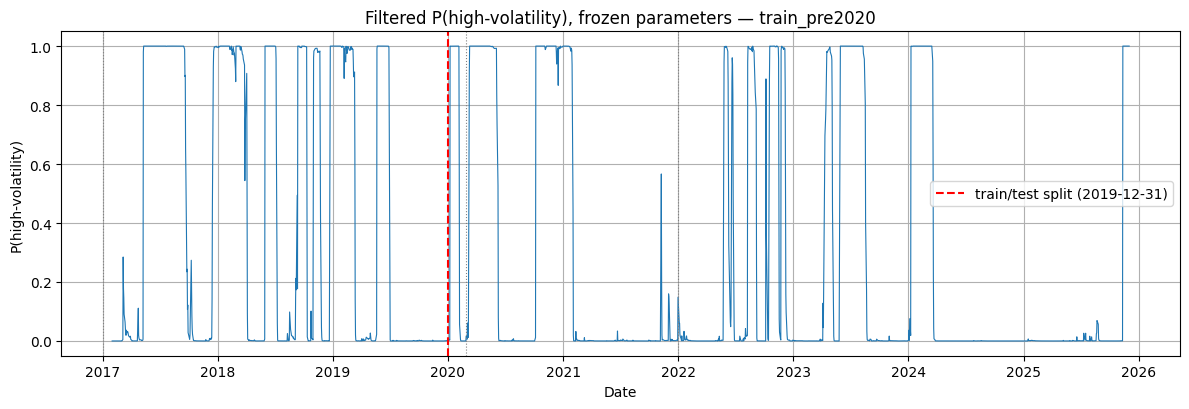

train_to2022: train to 2022-12-31  (n_train = 1467, n_test = 721)
Training-window mean volatility by state (high is the larger):
High    0.0119
Low     0.0059
Name: Volatility, dtype: float64

High-volatility share of days (filtered, frozen parameters):
                   High-vol share  n days
Period     Sample                        
COVID      train            31.29     457
Post-COVID test             18.86     721
           train            29.44     248
Pre-COVID  train            43.70     762

Agreement with the full-sample HMM on test days: 98.8%
Forward test (every 20th day): mean next-20d vol | flagged high = 0.01050 (n=7), flagged low = 0.00555 (n=29); Welch p = 0.0222
Spearman correlation between P(high) today and next-20d realised vol (all test days): rho = 0.355


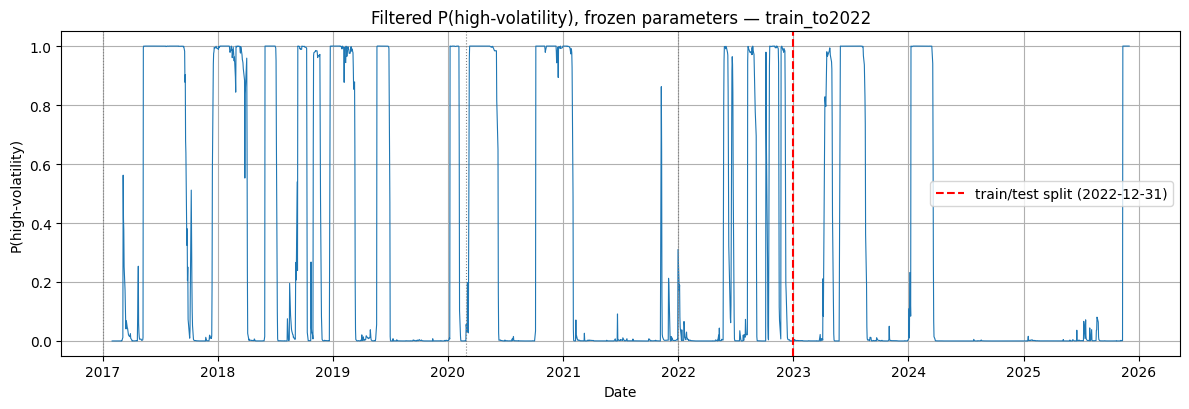


Saved hmm_oos_summary.csv and hmm_oos_state_share_by_period.csv


In [20]:
# ============================================================
# STEP 15 — OUT-OF-SAMPLE HMM
# ============================================================
def filtered_probs(model, X):
    # Forward-algorithm filtering with frozen parameters: P(state_t | x_1..x_t)
    K = len(model.startprob_)
    logB = np.column_stack([multivariate_normal.logpdf(X, mean=model.means_[k], cov=model.covars_[k],
                                                       allow_singular=True) for k in range(K)])
    A = model.transmat_
    out = np.zeros((len(X), K))
    prior = model.startprob_.copy()
    for t in range(len(X)):
        a = prior * np.exp(logB[t] - logB[t].max())
        a = a / a.sum()
        out[t] = a
        prior = a @ A
    return out

def fit_best(X, n_restarts=N_RESTARTS):
    best = None
    for seed in range(n_restarts):
        try:
            m = GaussianHMM(n_components=2, covariance_type="full", n_iter=1000, random_state=seed).fit(X)
            ll = m.score(X)
        except Exception:
            continue
        if best is None or ll > best[1]:
            best = (m, ll)
    return best[0]

ngx_ret_s = ngx.set_index("Date")["Return"]
fwd_vol = ngx_ret_s.rolling(FWD_WINDOW).std().shift(-FWD_WINDOW)     # std of returns t+1 .. t+20

def run_oos(train_end, tag):
    d = hmm_data.copy()
    is_train = d["Date"] <= pd.Timestamp(train_end)
    scaler = StandardScaler().fit(d.loc[is_train, ["Return", "Volatility"]])     # train-only scaling
    X_all = scaler.transform(d[["Return", "Volatility"]])
    X_tr = X_all[is_train.values]

    model = fit_best(X_tr)
    # label states by TRAINING-window mean volatility
    tr_states = model.predict(X_tr)
    tr_vol = d.loc[is_train, "Volatility"].groupby(tr_states).mean()
    high_id = int(tr_vol.idxmax())

    probs = filtered_probs(model, X_all)              # frozen parameters, filtered over the whole sequence
    d["P_high"] = probs[:, high_id]
    d["Flag_high"] = d["P_high"] > 0.5
    d["Sample"] = np.where(is_train, "train", "test")
    d["FwdVol"] = d["Date"].map(fwd_vol)

    print("=" * 70)
    print(f"{tag}: train to {train_end}  (n_train = {int(is_train.sum())}, n_test = {int((~is_train).sum())})")
    print("=" * 70)
    print("Training-window mean volatility by state (high is the larger):")
    print(tr_vol.round(4).rename(index=lambda i: "High" if i == high_id else "Low"))

    # high-vol share by calendar period, split into train / test portions
    share = (d.groupby(["Period", "Sample"])["Flag_high"].agg(["mean", "count"])
             .rename(columns={"mean": "High-vol share", "count": "n days"}))
    share["High-vol share"] = (share["High-vol share"] * 100).round(2)
    print("\nHigh-volatility share of days (filtered, frozen parameters):")
    print(share)

    test = d[d["Sample"] == "test"].copy()
    # agreement with the full-sample (in-sample, smoothed) model on the same test days
    agree = (test["Flag_high"] == (test["State"] == "High-Volatility")).mean() * 100
    print(f"\nAgreement with the full-sample HMM on test days: {agree:.1f}%")

    # forward-looking evidence: next-20-day realised volatility conditional on today's flag
    t2 = test.dropna(subset=["FwdVol"]).iloc[::FWD_WINDOW]            # non-overlapping forward windows
    hi = t2.loc[t2["Flag_high"], "FwdVol"]; lo = t2.loc[~t2["Flag_high"], "FwdVol"]
    if len(hi) > 2 and len(lo) > 2:
        t_stat, t_p = stats.ttest_ind(hi, lo, equal_var=False)
        fwd_msg = (f"mean next-20d vol | flagged high = {hi.mean():.5f} (n={len(hi)}), flagged low = {lo.mean():.5f} "
                   f"(n={len(lo)}); Welch p = {t_p:.4f}")
    else:
        t_p = np.nan
        fwd_msg = f"too few flagged-high days in the test window (high n={len(hi)}, low n={len(lo)})"
    rho, rho_p = stats.spearmanr(test.dropna(subset=["FwdVol"])["P_high"], test.dropna(subset=["FwdVol"])["FwdVol"])
    print("Forward test (every 20th day):", fwd_msg)
    print(f"Spearman correlation between P(high) today and next-20d realised vol (all test days): "
          f"rho = {rho:.3f}")

    d[["Date", "Period", "Sample", "P_high", "Flag_high", "State", "Volatility", "FwdVol"]].to_csv(
        OUT_DIR + f"hmm_oos_daily_{tag}.csv", index=False)

    fig, ax = plt.subplots(figsize=(12, 4.2))
    ax.plot(d["Date"], d["P_high"], lw=0.8)
    ax.axvline(pd.Timestamp(train_end), color="red", ls="--", label=f"train/test split ({train_end})")
    for lab, (s, e) in PERIODS.items():
        ax.axvline(pd.Timestamp(s), color="grey", ls=":", lw=0.8)
    ax.set_title(f"Filtered P(high-volatility), frozen parameters — {tag}")
    ax.set_xlabel("Date"); ax.set_ylabel("P(high-volatility)"); ax.legend(); ax.grid(True)
    plt.tight_layout(); plt.savefig(OUT_DIR + f"hmm_oos_prob_{tag}.png", dpi=150); plt.show()

    summary = {"Split": tag, "Train end": train_end, "n train": int(is_train.sum()), "n test": int((~is_train).sum()),
               "Agreement with full-sample HMM (%)": round(agree, 1),
               "Mean fwd vol | high flag": hi.mean() if len(hi) else np.nan, "n high": len(hi),
               "Mean fwd vol | low flag": lo.mean() if len(lo) else np.nan, "n low": len(lo),
               "Welch p (fwd vol, high vs low)": t_p, "Spearman rho (P_high vs fwd vol)": rho}
    return summary, share.reset_index().assign(Split=tag)

sum_a, share_a = run_oos("2019-12-31", "train_pre2020")
sum_b, share_b = run_oos("2022-12-31", "train_to2022")

pd.DataFrame([sum_a, sum_b]).to_csv(OUT_DIR + "hmm_oos_summary.csv", index=False)
pd.concat([share_a, share_b]).to_csv(OUT_DIR + "hmm_oos_state_share_by_period.csv", index=False)
print("\nSaved hmm_oos_summary.csv and hmm_oos_state_share_by_period.csv")

## STEP 16 — Economic significance, benchmark and sensitivity analysis

In [21]:
# ============================================================
# STEP 16 — ROBUSTNESS, ECONOMIC SIGNIFICANCE AND BENCHMARK
# ============================================================
# 17A. Economic significance: annualised volatility and 1-day historical VaR by period
def risk_table(ret_dict):
    rows = []
    for name, s in ret_dict.items():
        for per, (a, b) in PERIODS.items():
            x = s.loc[a:b].dropna()
            rows.append({"Series": name, "Period": per, "n": len(x),
                         "Annualised vol (%)": x.std() * np.sqrt(252) * 100,
                         "VaR 95% (1-day, %)": -np.percentile(x, 5) * 100,
                         "VaR 99% (1-day, %)": -np.percentile(x, 1) * 100})
    return pd.DataFrame(rows)

risk = risk_table({"NGX": ngx.set_index("Date")["Return"],
                   "USD/NGN": usd_ngn.set_index("Date")["Return"],
                   "Brent": brent.set_index("Date")["Return"]})
risk.to_csv(OUT_DIR + "economic_significance_var.csv", index=False)
print(risk.round(3).to_string(index=False))

# NGX risk conditional on the HMM regime (value of the regime flag to a risk manager)
ngx_r = ngx.set_index("Date")["Return"]
hd = hmm_data.set_index("Date")
reg_rows = []
for st in ["High-Volatility", "Low-Volatility"]:
    x = ngx_r.reindex(hd.index[hd["State"] == st]).dropna()
    reg_rows.append({"HMM state": st, "n": len(x), "Mean daily return (%)": x.mean() * 100,
                     "Annualised vol (%)": x.std() * np.sqrt(252) * 100,
                     "VaR 95% (1-day, %)": -np.percentile(x, 5) * 100,
                     "VaR 99% (1-day, %)": -np.percentile(x, 1) * 100,
                     "Excess kurtosis within state": stats.kurtosis(x, fisher=True)})
regime_risk = pd.DataFrame(reg_rows)
regime_risk.to_csv(OUT_DIR + "regime_conditional_risk.csv", index=False)
print("\nNGX risk conditional on HMM state:")
print(regime_risk.round(3).to_string(index=False))
print(f"Excess kurtosis of all NGX returns = {stats.kurtosis(ngx_r.dropna(), fisher=True):.2f}")

# Stress-regime definition: do correlations and mean returns differ by state?
cm = pd.concat([ngx_r.rename("NGX"), usd_ngn.set_index("Date")["Return"].rename("USD_NGN"),
                brent.set_index("Date")["Return"].rename("Brent")], axis=1, sort=True).dropna()
cm["State"] = hd["State"].reindex(cm.index)
cm = cm.dropna(subset=["State"])
st_rows = []
for st, g in cm.groupby("State"):
    for a, b in [("NGX", "Brent"), ("NGX", "USD_NGN"), ("USD_NGN", "Brent")]:
        r, p = stats.pearsonr(g[a], g[b])
        st_rows.append({"State": st, "Pair": f"{a} vs {b}", "n": len(g), "r": r, "p": p})
state_corr = pd.DataFrame(st_rows)
state_corr.to_csv(OUT_DIR + "correlation_by_hmm_state.csv", index=False)
print("\nCorrelations by HMM state:")
print(state_corr.round(4).to_string(index=False))

# 17B. Benchmark: simple volatility-threshold classifier versus the HMM (out-of-sample, train to 2022-12-31)
oos = pd.read_csv(OUT_DIR + "hmm_oos_daily_train_to2022.csv", parse_dates=["Date"])
train = oos[oos["Sample"] == "train"]; test = oos[oos["Sample"] == "test"].dropna(subset=["FwdVol"]).copy()
thr = train["Volatility"].median()
test["Flag_threshold"] = test["Volatility"] > thr
def switches(flag):
    f = pd.Series(flag).astype(int).values
    return int(np.abs(np.diff(f)).sum())
bench_rows = []
for name, series in [("HMM filtered P(high)", test["P_high"]),
                     ("HMM flag (P>0.5)", test["Flag_high"].astype(int)),
                     ("Threshold flag (20d vol > training median)", test["Flag_threshold"].astype(int))]:
    rho, p = stats.spearmanr(series, test["FwdVol"])
    flag = (series > 0.5) if name.startswith("HMM filtered") else series.astype(bool)
    bench_rows.append({"Classifier": name, "Spearman rho with next-20d vol": rho, "p": p,
                       "Share flagged high (%)": flag.mean() * 100,
                       "Regime switches (test)": switches(flag)})
bench = pd.DataFrame(bench_rows)
bench.to_csv(OUT_DIR + "benchmark_threshold_vs_hmm.csv", index=False)
print("\nBenchmark (test window 2023-2025):")
print(bench.round(4).to_string(index=False))

# 17C. Sensitivity: rolling-window length and random initialisation (2-state HMM, full sample)
def share_table(window, seed):
    r = ngx.set_index("Date")["Return"]
    d = pd.DataFrame({"Return": r, "Volatility": r.rolling(window).std()}).dropna()
    X = StandardScaler().fit_transform(d[["Return", "Volatility"]])
    m = GaussianHMM(n_components=2, covariance_type="full", n_iter=1000, random_state=seed).fit(X)
    reg = m.predict(X); ll = m.score(X)
    vm = d.groupby(reg)["Volatility"].mean(); high = vm.idxmax()
    d["High"] = (reg == high)
    out = {"Window": window, "Seed": seed, "Log-lik": ll}
    for per, (a, b) in PERIODS.items():
        out[per + " high-vol %"] = d.loc[a:b, "High"].mean() * 100
    return out
sens = pd.DataFrame([share_table(w, 42) for w in (10, 20, 60)] +
                    [share_table(20, s) for s in (0, 1, 2, 3, 4)])
sens.to_csv(OUT_DIR + "hmm_sensitivity.csv", index=False)
print("\nSensitivity (window length and random initialisation):")
print(sens.round(2).to_string(index=False))

# 17D. Alternative float anchor: subsidy-removal date (29 May 2023) versus FX-window unification (14 June 2023)
alt_rows = []
hs = hmm_data.set_index("Date")["State"]
for lab, dt in [("Subsidy removal (29 May 2023)", "2023-05-29"), ("FX windows unified (14 June 2023)", "2023-06-14")]:
    t0 = pd.Timestamp(dt)
    a = (hs.loc["2022-01-01":t0] == "High-Volatility"); b = (hs.loc[t0 + pd.Timedelta(days=1):END_DATE] == "High-Volatility")
    pa, pb, na, nb_ = a.mean(), b.mean(), len(a), len(b)
    pp = (a.sum() + b.sum()) / (na + nb_); z = (pa - pb) / np.sqrt(pp * (1 - pp) * (1 / na + 1 / nb_))
    alt_rows.append({"Anchor": lab, "n pre": na, "n post": nb_, "High-vol share pre (%)": pa * 100,
                     "High-vol share post (%)": pb * 100, "z": z, "p": 2 * (1 - stats.norm.cdf(abs(z)))})
alt_anchor = pd.DataFrame(alt_rows)
alt_anchor.to_csv(OUT_DIR + "naira_float_alt_anchor.csv", index=False)
print("\nAlternative float anchors:")
print(alt_anchor.round(4).to_string(index=False))

 Series     Period    n  Annualised vol (%)  VaR 95% (1-day, %)  VaR 99% (1-day, %)
    NGX  Pre-COVID  781              14.847               1.313               2.437
    NGX      COVID  457              15.073               1.370               2.445
    NGX Post-COVID  969              12.388               1.117               2.023
USD/NGN  Pre-COVID  822              21.204               2.837               4.696
USD/NGN      COVID  482              15.821               0.017               0.134
USD/NGN Post-COVID 1021              34.654               1.507               7.383
  Brent  Pre-COVID  804              29.959               3.173               5.091
  Brent      COVID  468              87.350               5.138              17.092
  Brent Post-COVID 1010              35.424               3.726               6.315

NGX risk conditional on HMM state:
      HMM state    n  Mean daily return (%)  Annualised vol (%)  VaR 95% (1-day, %)  VaR 99% (1-day, %)  Excess kurtosis wit

## STEP 17 — Figures

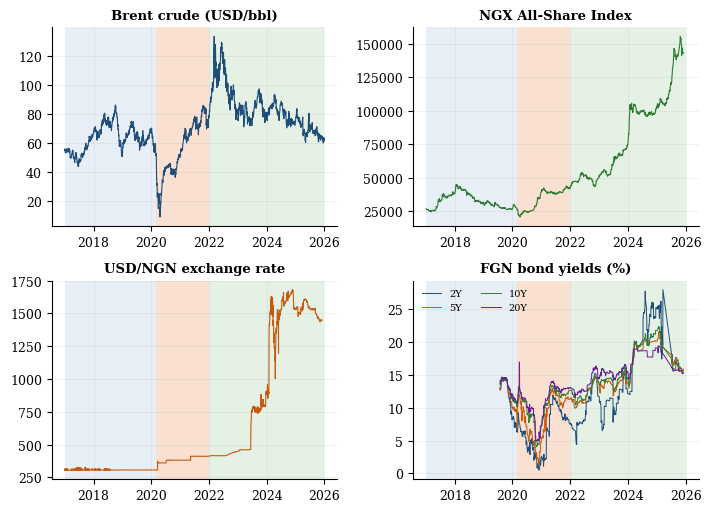

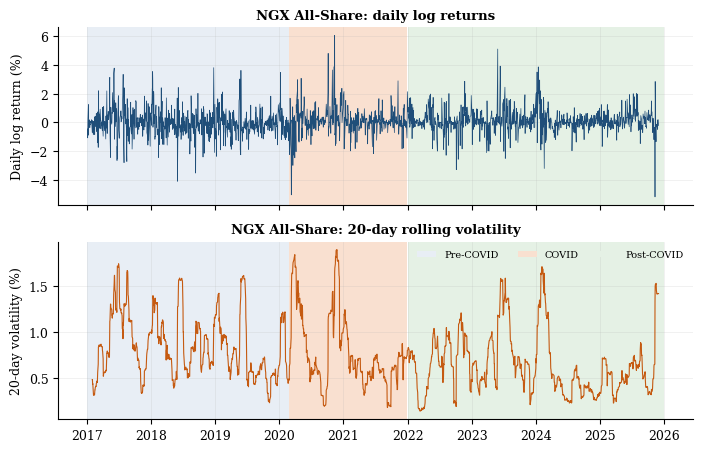

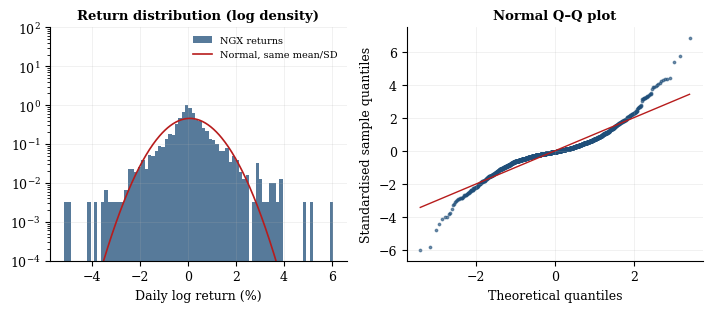

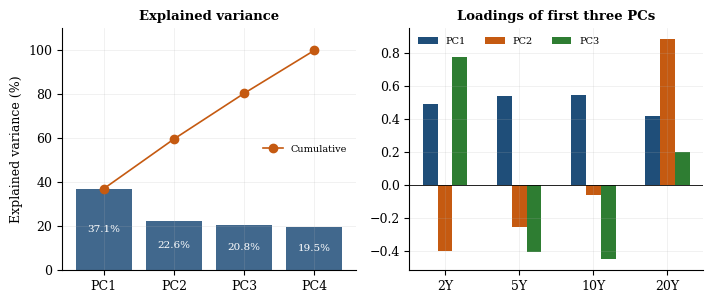

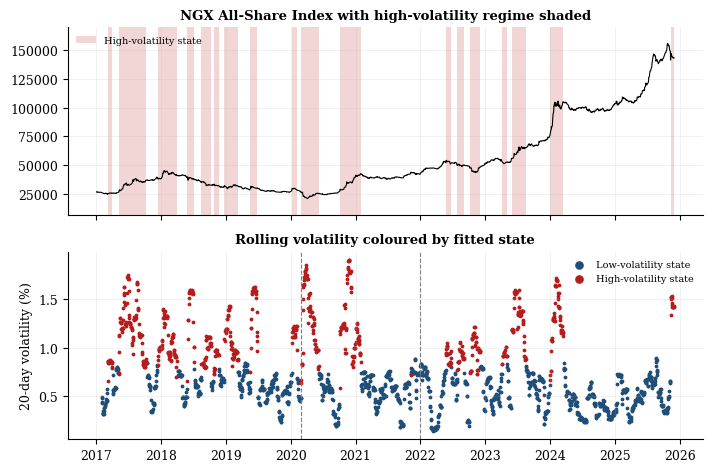

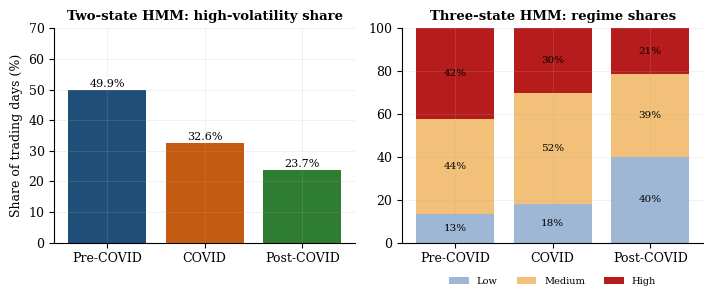

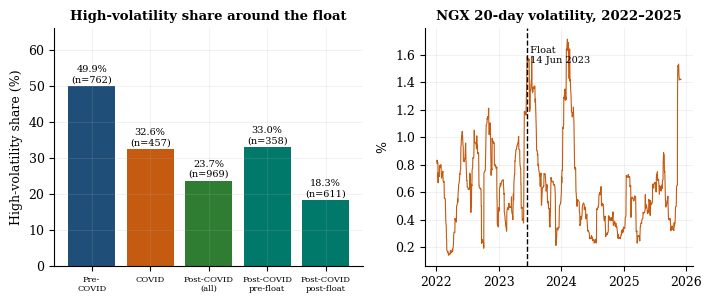

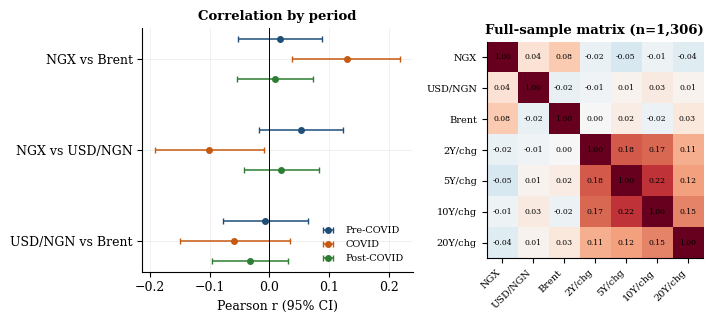

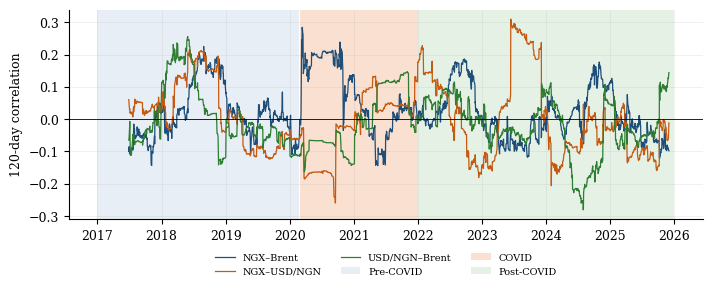

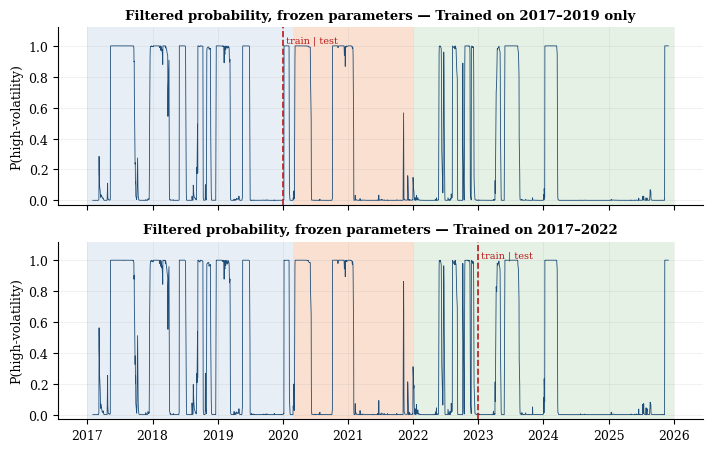

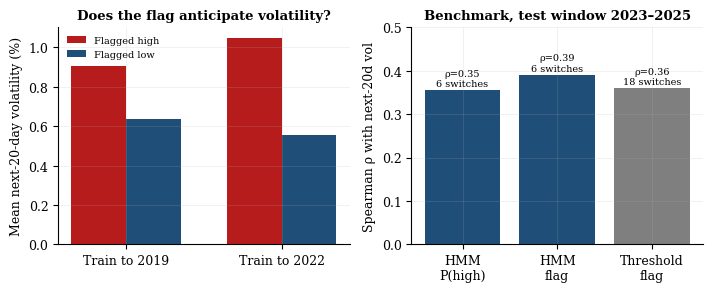

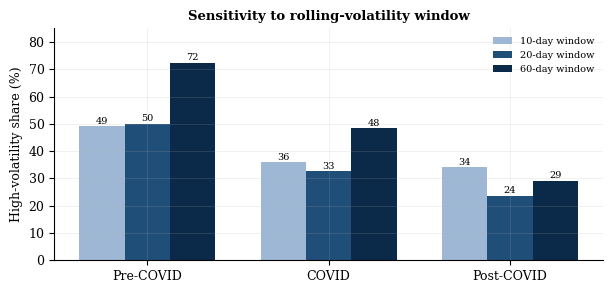

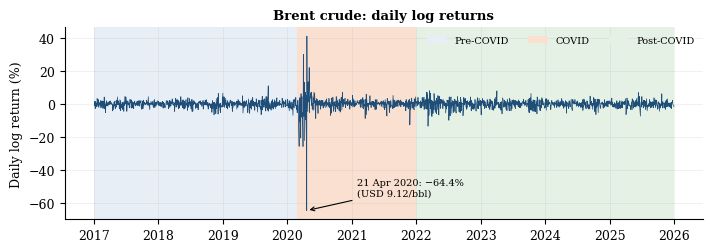

Saved 13 figures to /content/results/figures/


In [22]:
# ============================================================
# STEP 17 — FIGURES USED IN THE REPORT (saved to results/figures/)
# ============================================================
import matplotlib.dates as mdates
FIG_DIR = OUT_DIR + "figures/"
os.makedirs(FIG_DIR, exist_ok=True)
bj, hd = bond_joint, hmm_data
usd = usd_ngn
P = PERIODS
plt.rcParams.update({"font.family":"serif","font.serif":["Times New Roman","DejaVu Serif"],"font.size":9,
 "axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.25,"grid.linewidth":.5,
 "axes.titlesize":9.5,"axes.titleweight":"bold","figure.dpi":100,"savefig.dpi":220,"savefig.bbox":"tight"})
C={"blue":"#1F4E79","orange":"#C55A11","grey":"#7F7F7F","green":"#2E7D32","red":"#B71C1C","teal":"#00796B","purple":"#6A1B9A"}
SHADE={"Pre-COVID":"#E8EEF5","COVID":"#F9E0D0","Post-COVID":"#E5F1E5"}
def shade(ax,labels=False):
    for k,(a,b) in PERIODS.items():
        ax.axvspan(pd.Timestamp(a),pd.Timestamp(b),color=SHADE[k],lw=0,zorder=0,label=k if labels else None)
def fmt(ax,step=1):
    ax.xaxis.set_major_locator(mdates.YearLocator(step)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
def save(name): plt.savefig(FIG_DIR+name); plt.show()

# Fig 1 price series
fig,axs=plt.subplots(2,2,figsize=(7.2,5.2))
for ax,(d,t,c) in zip(axs.flat[:3],[(brent,"Brent crude (USD/bbl)",C['blue']),(ngx,"NGX All-Share Index",C['green']),(usd,"USD/NGN exchange rate",C['orange'])]):
    shade(ax); ax.plot(d["Date"],d["Price"],lw=.8,color=c); ax.set_title(t); fmt(ax,2)
ax=axs[1,1]; shade(ax)
for col,lab,c in zip(BOND_COLS,["2Y","5Y","10Y","20Y"],[C['blue'],C['orange'],C['green'],C['purple']]):
    ax.plot(bj["Date"],bj[col],lw=.7,color=c,label=lab)
ax.set_title("FGN bond yields (%)"); fmt(ax,2)
ax.legend(ncol=2,fontsize=7,frameon=False,loc="upper left")
plt.tight_layout(); save("fig01_series.png")

# Fig 2 returns & volatility NGX
fig,axs=plt.subplots(2,1,figsize=(7.2,4.6),sharex=True)
shade(axs[0]); axs[0].plot(ngx["Date"],ngx["Return"]*100,lw=.5,color=C['blue']); axs[0].set_ylabel("Daily log return (%)"); axs[0].set_title("NGX All-Share: daily log returns")
shade(axs[1],True); axs[1].plot(ngx["Date"],ngx["Volatility"]*100,lw=.8,color=C['orange']); axs[1].set_ylabel("20-day volatility (%)"); axs[1].set_title("NGX All-Share: 20-day rolling volatility"); fmt(axs[1])
axs[1].legend(ncol=3,fontsize=7,frameon=False,loc="upper right")
plt.tight_layout(); save("fig02_ngx_ret_vol.png")

# Fig 3 distribution / fat tails
r=ngx["Return"].dropna().values*100
fig,axs=plt.subplots(1,2,figsize=(7.2,3.2))
ax=axs[0]; ax.hist(r,bins=80,density=True,color=C['blue'],alpha=.75,label="NGX returns")
xs=np.linspace(r.min(),r.max(),400); ax.plot(xs,stats.norm.pdf(xs,r.mean(),r.std()),color=C['red'],lw=1.2,label="Normal, same mean/SD")
ax.set_yscale("log"); ax.set_ylim(1e-4,1e2); ax.set_title("Return distribution (log density)"); ax.set_xlabel("Daily log return (%)"); ax.legend(fontsize=7,frameon=False)
ax=axs[1]; (osm,osr),(sl,ic,rr)=stats.probplot((r-r.mean())/r.std(),dist="norm")
ax.scatter(osm,osr,s=3,color=C['blue'],alpha=.6); ax.plot(osm,osm,color=C['red'],lw=1); ax.set_title("Normal Q–Q plot"); ax.set_xlabel("Theoretical quantiles"); ax.set_ylabel("Standardised sample quantiles")
plt.tight_layout(); save("fig03_tails.png")

# Fig 4 PCA
ev=pca.explained_variance_ratio_*100; ld=loadings
fig,axs=plt.subplots(1,2,figsize=(7.2,3.1))
ax=axs[0]; ax.bar(["PC1","PC2","PC3","PC4"],ev,color=C['blue'],alpha=.85); ax.plot(range(4),np.cumsum(ev),marker="o",color=C['orange'],lw=1.2,label="Cumulative")
for i,v in enumerate(ev): ax.text(i,v/2,f"{v:.1f}%",ha="center",va="center",fontsize=7.5,color="white")
ax.set_ylim(0,110); ax.set_ylabel("Explained variance (%)"); ax.set_title("Explained variance"); ax.legend(fontsize=7,frameon=False,loc="center right")
ax=axs[1]; x=np.arange(4); w=.2
for i,(pc,c) in enumerate(zip(["PC1","PC2","PC3"],[C['blue'],C['orange'],C['green']])):
    ax.bar(x+(i-1)*w,ld[pc].values,w,label=pc,color=c)
ax.set_xticks(x); ax.set_xticklabels(["2Y","5Y","10Y","20Y"]); ax.axhline(0,color="k",lw=.6); ax.set_title("Loadings of first three PCs"); ax.legend(fontsize=7,frameon=False,ncol=3)
plt.tight_layout(); save("fig04_pca.png")

# Fig 5 HMM regimes
fig,axs=plt.subplots(2,1,figsize=(7.2,4.8),sharex=True)
px=ngx.set_index("Date")["Price"]; hs=hd.set_index("Date")["State"]
ax=axs[0]; ax.plot(px.index,px.values,lw=.8,color="k")
hi=(hs=="High-Volatility").reindex(px.index).fillna(False).values
ax.fill_between(px.index,0,1,where=hi,transform=ax.get_xaxis_transform(),color=C['red'],alpha=.18,lw=0,label="High-volatility state")
ax.set_title("NGX All-Share Index with high-volatility regime shaded"); ax.legend(fontsize=7,frameon=False,loc="upper left")
ax=axs[1]; v=hd.set_index("Date")["Volatility"]*100
ax.scatter(v.index[hs=="Low-Volatility"],v[hs=="Low-Volatility"],s=3,color=C['blue'],label="Low-volatility state")
ax.scatter(v.index[hs=="High-Volatility"],v[hs=="High-Volatility"],s=3,color=C['red'],label="High-volatility state")
for k,(a,b) in PERIODS.items():
    if k!="Pre-COVID": ax.axvline(pd.Timestamp(a),color=C['grey'],ls="--",lw=.8)
ax.set_ylabel("20-day volatility (%)"); ax.set_title("Rolling volatility coloured by fitted state"); ax.legend(fontsize=7,frameon=False,markerscale=3); fmt(ax)
plt.tight_layout(); save("fig05_hmm_regimes.png")

# Fig 6 regime shares by period: 2-state and 3-state
s2=pd.read_csv(OUT_DIR+"hmm_2state_regime_shares.csv"); s3=pd.read_csv(OUT_DIR+"hmm_3state_regime_shares.csv")

# Fig 6 regime shares
fig,axs=plt.subplots(1,2,figsize=(7.2,3.1))
ax=axs[0]; per=["Pre-COVID","COVID","Post-COVID"]
v=s2["High-Volatility"].values; bars=ax.bar(per,v,color=[C['blue'],C['orange'],C['green']])
for b,x in zip(bars,v): ax.text(b.get_x()+b.get_width()/2,x+1,f"{x:.1f}%",ha="center",fontsize=8)
ax.set_ylim(0,70); ax.set_ylabel("Share of trading days (%)"); ax.set_title("Two-state HMM: high-volatility share")
ax=axs[1]; bot=np.zeros(3)
for col,c in zip(["Low-Volatility","Medium-Volatility","High-Volatility"],["#9DB7D5","#F2C078",C['red']]):
    vals=s3[col].values; ax.bar(per,vals,bottom=bot,color=c,label=col.replace("-Volatility",""))
    for i,(vv,bb) in enumerate(zip(vals,bot)): ax.text(i,bb+vv/2,f"{vv:.0f}%",ha="center",va="center",fontsize=7.5)
    bot+=vals
ax.set_ylim(0,100); ax.set_title("Three-state HMM: regime shares"); ax.legend(fontsize=7,frameon=False,ncol=3,loc="upper center",bbox_to_anchor=(.5,-.12))
plt.tight_layout(); save("fig06_regime_shares.png")

# Fig 7 naira float
nt=pd.read_csv(OUT_DIR+"naira_float_subperiod_regime_shares.csv")
fig,axs=plt.subplots(1,2,figsize=(7.2,3.1),gridspec_kw={"width_ratios":[1.15,1]})
ax=axs[0]; lab=["Pre-\nCOVID","COVID","Post-COVID\n(all)","Post-COVID\npre-float","Post-COVID\npost-float"][:len(nt)]
cols=[C['blue'],C['orange'],"#7FB77E",C['green']] if len(nt)==5 else [C['blue'],C['orange'],C['green']]
cols=[C['blue'],C['orange'],C['green'],C['teal'],C['teal']][:len(nt)]
bars=ax.bar(range(len(nt)),nt["High-Volatility share (%)"],color=cols)
for b,x,n in zip(bars,nt["High-Volatility share (%)"],nt["n days"]): ax.text(b.get_x()+b.get_width()/2,x+1,f"{x:.1f}%\n(n={n})",ha="center",fontsize=7)
ax.set_xticks(range(len(nt))); ax.set_xticklabels(lab,fontsize=6); ax.set_ylim(0,66); ax.set_ylabel("High-volatility share (%)"); ax.set_title("High-volatility share around the float")
ax=axs[1]; p=ngx.set_index("Date")["Volatility"].loc["2022-01-01":]*100
ax.plot(p.index,p.values,lw=.8,color=C['orange']); fd=pd.Timestamp("2023-06-14"); ax.axvline(fd,color="k",ls="--",lw=1); ax.text(fd,ax.get_ylim()[1]*.93," Float\n 14 Jun 2023",fontsize=7,va="top")
ax.set_title("NGX 20-day volatility, 2022–2025"); ax.set_ylabel("%"); fmt(ax)
plt.tight_layout(); save("fig07_naira_float.png")

# Fig 8 correlation by period (forest) + full matrix heatmap
cp=pd.read_csv(OUT_DIR+"correlation_by_period.csv"); mk3=cp[cp["Sample"].str.startswith("3 markets")]
fig,axs=plt.subplots(1,2,figsize=(7.2,3.3),gridspec_kw={"width_ratios":[1.25,1]})
ax=axs[0]; pairs=["NGX vs Brent","NGX vs USD_NGN","USD_NGN vs Brent"]; off={"Pre-COVID":-.22,"COVID":0,"Post-COVID":.22}; colr={"Pre-COVID":C['blue'],"COVID":C['orange'],"Post-COVID":C['green']}
for per_ in off:
    d=mk3[mk3["Period"]==per_].set_index("Pair").loc[pairs]
    y=np.arange(3)+off[per_]
    ax.errorbar(d["r"],y,xerr=[d["r"]-d["95% CI low"],d["95% CI high"]-d["r"]],fmt="o",ms=4,lw=1.1,color=colr[per_],label=per_,capsize=2)
ax.axvline(0,color="k",lw=.7); ax.set_yticks(range(3)); ax.set_yticklabels([p.replace("_","/") for p in pairs]); ax.invert_yaxis()
ax.set_xlabel("Pearson r (95% CI)"); ax.set_title("Correlation by period"); ax.legend(fontsize=7,frameon=False,loc="lower right")
ax=axs[1]; cm=corr_matrix.copy(); cm.columns=[c.replace("_","/") for c in cm.columns]; cm.index=cm.columns
im=ax.imshow(cm.values,cmap="RdBu_r",vmin=-.3,vmax=.3); ax.set_xticks(range(len(cm))); ax.set_yticks(range(len(cm)))
ax.set_xticklabels(cm.columns,rotation=45,ha="right",fontsize=7); ax.set_yticklabels(cm.columns,fontsize=7); ax.grid(False)
for i in range(len(cm)):
    for j in range(len(cm)): ax.text(j,i,f"{cm.values[i,j]:.2f}",ha="center",va="center",fontsize=5.5)
ax.set_title("Full-sample matrix (n=1,306)")
plt.tight_layout(); save("fig08_correlations.png")

# Fig 9 rolling correlations
mkr=pd.concat([ngx.set_index("Date")["Return"].rename("NGX"),usd.set_index("Date")["Return"].rename("USD/NGN"),brent.set_index("Date")["Return"].rename("Brent")],axis=1,sort=True).dropna()
fig,ax=plt.subplots(figsize=(7.2,3.0)); shade(ax,True)
for (a,b),c in zip([("NGX","Brent"),("NGX","USD/NGN"),("USD/NGN","Brent")],[C['blue'],C['orange'],C['green']]):
    ax.plot(mkr.index,mkr[a].rolling(120).corr(mkr[b]),lw=.9,color=c,label=f"{a}–{b}")
ax.axhline(0,color="k",lw=.6); ax.set_ylabel("120-day correlation"); fmt(ax)
h,l=ax.get_legend_handles_labels(); ax.legend(h[3:]+h[:3],l[3:]+l[:3],fontsize=7,frameon=False,ncol=3,loc="upper center",bbox_to_anchor=(.5,-.12))
plt.tight_layout(); save("fig09_rolling_corr.png")

# Fig 10 out-of-sample probabilities
fig,axs=plt.subplots(2,1,figsize=(7.2,4.6),sharex=True)
for ax,(tag,te,title) in zip(axs,[("train_pre2020","2019-12-31","Trained on 2017–2019 only"),("train_to2022","2022-12-31","Trained on 2017–2022")]):
    d=pd.read_csv(OUT_DIR+f"hmm_oos_daily_{tag}.csv",parse_dates=["Date"]); shade(ax)
    ax.plot(d["Date"],d["P_high"],lw=.6,color=C['blue']); ax.axvline(pd.Timestamp(te),color=C['red'],ls="--",lw=1.2)
    ax.text(pd.Timestamp(te),1.02," train | test",fontsize=7,color=C['red']); ax.set_ylim(-.03,1.12); ax.set_ylabel("P(high-volatility)"); ax.set_title(f"Filtered probability, frozen parameters — {title}")
fmt(axs[1]); plt.tight_layout(); save("fig10_oos.png")

# Fig 11 forward test + benchmark
sm=pd.read_csv(OUT_DIR+"hmm_oos_summary.csv"); bm=pd.read_csv(OUT_DIR+"benchmark_threshold_vs_hmm.csv")
fig,axs=plt.subplots(1,2,figsize=(7.2,3.0))
ax=axs[0]; x=np.arange(2); w=.35
ax.bar(x-w/2,sm["Mean fwd vol | high flag"]*100,w,color=C['red'],label="Flagged high"); ax.bar(x+w/2,sm["Mean fwd vol | low flag"]*100,w,color=C['blue'],label="Flagged low")
ax.set_xticks(x); ax.set_xticklabels(["Train to 2019","Train to 2022"]); ax.set_ylabel("Mean next-20-day volatility (%)"); ax.set_title("Does the flag anticipate volatility?"); ax.legend(fontsize=7,frameon=False)
ax=axs[1]; names=["HMM\nP(high)","HMM\nflag","Threshold\nflag"]; ax.bar(names,bm["Spearman rho with next-20d vol"],color=[C['blue'],C['blue'],C['grey']])
for i,(rho,s) in enumerate(zip(bm["Spearman rho with next-20d vol"],bm["Regime switches (test)"])): ax.text(i,rho+.01,f"ρ={rho:.2f}\n{s} switches",ha="center",fontsize=7)
ax.set_ylim(0,.5); ax.set_title("Benchmark, test window 2023–2025"); ax.set_ylabel("Spearman ρ with next-20d vol")
plt.tight_layout(); save("fig11_forward_benchmark.png")

# Fig 12 sensitivity
se=pd.read_csv(OUT_DIR+"hmm_sensitivity.csv"); se=se[se["Seed"]==42]
fig,ax=plt.subplots(figsize=(6.2,3.0)); x=np.arange(3); w=.25
for i,(wn,c) in enumerate(zip([10,20,60],["#9DB7D5",C['blue'],"#0B2A4A"])):
    r_=se[se["Window"]==wn].iloc[0]; vals=[r_["Pre-COVID high-vol %"],r_["COVID high-vol %"],r_["Post-COVID high-vol %"]]
    ax.bar(x+(i-1)*w,vals,w,color=c,label=f"{wn}-day window")
    for xi,v in zip(x+(i-1)*w,vals): ax.text(xi,v+1,f"{v:.0f}",ha="center",fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(per); ax.set_ylabel("High-volatility share (%)"); ax.set_title("Sensitivity to rolling-volatility window"); ax.legend(fontsize=7,frameon=False); ax.set_ylim(0,85)
plt.tight_layout(); save("fig12_sensitivity.png")

# Fig 13 Brent return event
fig,ax=plt.subplots(figsize=(7.2,2.6)); shade(ax,True); ax.plot(brent["Date"],brent["Return"]*100,lw=.5,color=C['blue'])
ev=brent.loc[brent["Return"].idxmin()]; ax.annotate("21 Apr 2020: −64.4%\n(USD 9.12/bbl)",xy=(ev["Date"],ev["Return"]*100),xytext=(pd.Timestamp("2021-02-01"),-55),fontsize=7,arrowprops=dict(arrowstyle="->",lw=.8))
ax.set_ylabel("Daily log return (%)"); ax.set_title("Brent crude: daily log returns"); fmt(ax); ax.legend(fontsize=7,frameon=False,ncol=3,loc="upper right")
plt.tight_layout(); save("fig13_brent.png")
print("Saved", len(os.listdir(FIG_DIR)), "figures to", FIG_DIR)

## STEP 18 — Package results

In [23]:
# ============================================================
# STEP 18 — ZIP AND DOWNLOAD ALL RESULTS
# ============================================================
import shutil
ZIP_BASE = os.path.join(os.path.dirname(os.path.normpath(OUT_DIR)), "project_results")
shutil.make_archive(ZIP_BASE, "zip", OUT_DIR)
print("Files written:")
for f in sorted(os.listdir(OUT_DIR)):
    print("  ", f)

try:
    from google.colab import files
    files.download(ZIP_BASE + ".zip")
except Exception:
    print("Not running in Colab - results are in", OUT_DIR)

Files written:
   benchmark_threshold_vs_hmm.csv
   correlation_by_hmm_state.csv
   correlation_by_period.csv
   correlation_change_tests.csv
   correlation_matrix.csv
   economic_significance_var.csv
   figures
   hmm_2_vs_3_state_fit.csv
   hmm_2state_regime_shares.csv
   hmm_3state_regime_shares.csv
   hmm_3state_transition_matrix.csv
   hmm_oos_daily_train_pre2020.csv
   hmm_oos_daily_train_to2022.csv
   hmm_oos_prob_train_pre2020.png
   hmm_oos_prob_train_to2022.png
   hmm_oos_state_share_by_period.csv
   hmm_oos_summary.csv
   hmm_sensitivity.csv
   naira_float_alt_anchor.csv
   naira_float_break_tests.csv
   naira_float_subperiod_regime_shares.csv
   regime_conditional_risk.csv
   rolling_correlations.png
   stationarity_adf_kpss.csv
   welch_levene_full_table.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>